# 03 — KPI Calculations (revised)
**Week 3 — CadetX Heavy Supplier, Inventory & Warehouse Analytics**

**Source:** the five corrected Week-2 merged datasets (`sales_orders_full`, `invoices_with_payments`, `purchase_orders_full`, `inventory_with_ledger`, `stock_ledger_enriched`).

### What changed from the first Week-3 version
| # | Change | Why |
|---|---|---|
| 1 | **Revenue is now net of GST and excludes Cancelled orders** (gross-incl.-GST and cancelled value are reported separately) | The earlier ₹32.4B was `grand_total` (includes GST) and included 1,967 Cancelled orders |
| 2 | **"Not Invoiced" removed** — replaced by `Cancelled` (1,967) and the 393 repeated-ID invoices are kept in the invoiced base | Earlier label mixed cancelled orders with 393 orders that *do* have an invoice |
| 3 | **Supplier KPIs come from purchase orders** (spend, on-time rate, delay, lead time, cancellations) | Every product is bought from all 8 suppliers, so a "primary supplier per product" is arbitrary and supplier *sales* revenue is not meaningful |
| 4 | **Quantile stock-health and stock-based turnover removed as findings**; replaced by a stock-scale diagnostic | Quantile classes are ~25/50/25 by construction; stock is ~18× larger in scale than sales |
| 5 | Profit & margin added from the corrected `line_profit` | Corrected in the Week-2 rebuild |
| 6 | Payment outstanding/overdue only on rows with reliable payment totals | 393 repeated-ID invoices cannot be matched to their payments |
| 7 | Reads the merged files by explicit name and asserts row counts, totals and key uniqueness | Previous notebook read a file that was not in the submission |

## Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

# ── Paths ─ edit DATA_DIR if your merged files live elsewhere ────────────────
CANDIDATES = [Path("merged"), Path("data/merged"), Path("../reports/week_02/merged"), Path("../merged")]
DATA_DIR = next((p for p in CANDIDATES if (p / "sales_orders_full.csv").exists()), None)
assert DATA_DIR is not None, "Could not find the merged datasets – set DATA_DIR manually"
OUT_DIR   = Path("kpi_outputs");        OUT_DIR.mkdir(exist_ok=True)
CHART_DIR = Path("exploratory_charts"); CHART_DIR.mkdir(exist_ok=True)
print("Merged datasets :", DATA_DIR.resolve())

def save(df, name, index=False):
    df.to_csv(OUT_DIR / name, index=index); print(f"saved {name} ({len(df)} rows)")
def savefig(fig, name):
    # save the chart to exploratory_charts/ AND show it inline in the notebook
    fig.tight_layout(); fig.savefig(CHART_DIR / name, dpi=130, facecolor=fig.get_facecolor()); plt.show(); plt.close(fig); print("saved chart", name)

# ── Chart style: validated categorical palette (blue, orange, aqua), recessive grid, thin marks ─────────
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#b9b8b2"
plt.rcParams.update({"figure.facecolor":SURF, "axes.facecolor":SURF, "savefig.facecolor":SURF,
    "text.color":INK, "axes.labelcolor":INK2, "xtick.color":INK2, "ytick.color":INK2, "axes.edgecolor":MUTED,
    "axes.titleweight":"bold", "axes.titlesize":11, "axes.titlelocation":"left", "axes.spines.top":False, "axes.spines.right":False,
    "axes.grid":True, "grid.color":GRID, "grid.linewidth":.8, "axes.axisbelow":True, "legend.frameon":False, "font.size":9.5,
    "figure.dpi":110})
def figs(nrows=1, ncols=1, size=(11,4.2), **kw):
    fig, axs = plt.subplots(nrows, ncols, figsize=size, **kw); return fig, axs
def billions(ax, axis="x", dec=1):
    f = FuncFormatter(lambda v,_: f"₹{v:,.{dec}f}B")
    (ax.xaxis if axis=="x" else ax.yaxis).set_major_formatter(f)
def hbar(ax, labels, values, title, fmt="{:,.2f}", color=BLUE, xlabel=None, hi=None):
    # horizontal bars with the value labelled at the end of each bar (first item at the top)
    y = np.arange(len(labels))[::-1]; cols = [color]*len(labels)
    if hi is not None: cols[hi] = ORANGE
    ax.barh(y, values, color=cols, height=.62); ax.set_yticks(y); ax.set_yticklabels(labels)
    for yi,v in zip(y,values): ax.text(v, yi, "  "+fmt.format(v), va="center", fontsize=8.5, color=INK2)
    ax.set_title(title); ax.grid(axis="y", visible=False); ax.margins(x=.18)
    if xlabel: ax.set_xlabel(xlabel)
def inr_b(x): return f"₹{x/1e9:,.2f}B"
checks = []   # (check, expected, actual, passed) → validation report
def check(name, expected, actual, ok): checks.append((name, expected, actual, "PASS" if ok else "FAIL")); assert ok, name

Merged datasets : /tmp/claude-0/-home-claude/6bcba5f3-dda2-517e-bd95-e2227d15c22a/scratchpad/w3viz/merged


## 0. Load & integrity checks

In [2]:
sales = pd.read_csv(DATA_DIR/"sales_orders_full.csv",   low_memory=False, parse_dates=["order_date","delivery_date"])
inv   = pd.read_csv(DATA_DIR/"invoices_with_payments.csv", low_memory=False, parse_dates=["invoice_date","due_date","order_date","delivery_date","as_of_date"])
po    = pd.read_csv(DATA_DIR/"purchase_orders_full.csv", low_memory=False, parse_dates=["order_date","expected_delivery_date","received_date"])
invl  = pd.read_csv(DATA_DIR/"inventory_with_ledger.csv", low_memory=False)
led   = pd.read_csv(DATA_DIR/"stock_ledger_enriched.csv", low_memory=False, parse_dates=["movement_date"])

check("sales rows (line grain)",           130402, len(sales), len(sales)==130402)
check("sales key (so_id,line_number) unique", 0, int(sales.duplicated(["so_id","line_number"]).sum()), not sales.duplicated(["so_id","line_number"]).any())
check("unique orders",                     20000, sales.so_id.nunique(), sales.so_id.nunique()==20000)
check("invoice rows",                      18033, len(inv), len(inv)==18033)
check("PO rows (line grain)",              155495, len(po), len(po)==155495)
check("inventory pairs",                   180, len(invl), len(invl)==180)
check("ledger rows",                       237230, len(led), len(led)==237230)
amb = [c for df in (sales,inv,po,invl,led) for c in df.columns if c.endswith(("_x","_y","_dim"))]
check("no ambiguous _x/_y columns", 0, len(amb), len(amb)==0)
print(pd.DataFrame(checks, columns=["check","expected","actual","status"]).to_string(index=False))

                               check  expected  actual status
             sales rows (line grain)    130402  130402   PASS
sales key (so_id,line_number) unique         0       0   PASS
                       unique orders     20000   20000   PASS
                        invoice rows     18033   18033   PASS
                PO rows (line grain)    155495  155495   PASS
                     inventory pairs       180     180   PASS
                         ledger rows    237230  237230   PASS
          no ambiguous _x/_y columns         0       0   PASS


# Part A — Sales & Customer KPIs

### Revenue definitions (used throughout)
| Term | Definition |
|---|---|
| **Net revenue** | `total_order_value` (ex-GST) of **Delivered** orders |
| **Gross revenue** | `grand_total` (incl. GST) of Delivered orders |
| **Cancelled value** | ex-GST value of Cancelled orders — reported separately, **not** revenue |

The order status is `Delivered` or `Cancelled`; every Cancelled order has no invoice.

In [3]:
# one row per order (header fields repeat on every line)
orders = sales.drop_duplicates("so_id").copy()
orders["order_year"]  = orders.order_date.dt.year
orders["order_month"] = orders.order_date.dt.to_period("M").dt.to_timestamp()
orders["lead_time_days"] = (orders.delivery_date - orders.order_date).dt.days

# header totals must equal the sum of the lines
line_sum = sales.groupby("so_id").line_total.sum()
check("order header total == sum of lines (all orders)", 0, int(((orders.set_index("so_id").total_order_value - line_sum).abs()>1).sum()),
      ((orders.set_index("so_id").total_order_value - line_sum).abs()<=1).all())

deliv   = orders[orders.order_status=="Delivered"].copy()
cancel  = orders[orders.order_status=="Cancelled"].copy()
sales_d = sales[sales.order_status=="Delivered"].copy()          # delivered lines

print(orders.order_status.value_counts().to_string())

order_status
Delivered    18033
Cancelled     1967


## A.1 Top-line KPIs

In [4]:
kpi = {
 "orders_total":                 len(orders),
 "orders_delivered":             len(deliv),
 "orders_cancelled":             len(cancel),
 "cancellation_rate_pct":        round(len(cancel)/len(orders)*100,2),
 "net_revenue_ex_gst":           deliv.total_order_value.sum(),
 "gross_revenue_incl_gst":       deliv.grand_total.sum(),
 "gst_collected":                deliv.total_gst_amount.sum(),
 "cancelled_value_ex_gst":       cancel.total_order_value.sum(),
 "avg_order_value_net":          deliv.total_order_value.mean(),
 "gross_profit":                 sales_d.line_profit.sum(),
 "gross_margin_pct_of_net_rev":  sales_d.line_profit.sum()/sales_d.line_total.sum()*100,
 "avg_delivery_lead_time_days":  deliv.lead_time_days.mean(),
 "median_delivery_lead_time_days": deliv.lead_time_days.median(),
}
kpi_df = pd.DataFrame({"kpi":list(kpi), "value":[round(v,2) for v in kpi.values()]})
check("delivered+cancelled == all orders", 20000, len(deliv)+len(cancel), len(deliv)+len(cancel)==20000)
check("net revenue (delivered lines) == delivered order totals", 0, round(sales_d.line_total.sum()-deliv.total_order_value.sum(),2), abs(sales_d.line_total.sum()-deliv.total_order_value.sum())<1)
check("profit == qty*(price-cost)", 0, round((sales_d.quantity*(sales_d.unit_price-sales_d.unit_cost)-sales_d.line_profit).abs().max(),2),
      ((sales_d.quantity*(sales_d.unit_price-sales_d.unit_cost)-sales_d.line_profit).abs()<0.01).all())
save(kpi_df, "kpi_tables.csv"); kpi_df

saved kpi_tables.csv (13 rows)


                               kpi             value
0                     orders_total         20,000.00
1                 orders_delivered         18,033.00
2                 orders_cancelled          1,967.00
3            cancellation_rate_pct              9.84
4               net_revenue_ex_gst 22,958,987,430.00
5           gross_revenue_incl_gst 29,253,993,162.40
6                    gst_collected  6,295,005,732.40
7           cancelled_value_ex_gst  2,488,405,130.00
8              avg_order_value_net      1,273,165.17
9                     gross_profit  4,950,006,740.00
10     gross_margin_pct_of_net_rev             21.56
11     avg_delivery_lead_time_days              8.06
12  median_delivery_lead_time_days              8.00

## A.2 Net revenue by year and month (Delivered orders)

In [5]:
rev_year = deliv.groupby("order_year").agg(net_revenue=("total_order_value","sum"), orders=("so_id","count"),
                                           avg_order_value=("total_order_value","mean")).round(2).reset_index()
rev_year["yoy_pct"] = (rev_year.net_revenue.pct_change()*100).round(2)
rev_month = deliv.groupby("order_month").total_order_value.sum().round(2).rename("net_revenue").reset_index()
save(rev_year,"kpi_revenue_by_year.csv"); save(rev_month,"kpi_revenue_by_month.csv"); rev_year

saved kpi_revenue_by_year.csv (6 rows)
saved kpi_revenue_by_month.csv (72 rows)


   order_year  net_revenue  orders  avg_order_value  yoy_pct
0        2019   3870016600    3031     1,276,811.81      NaN
1        2020   3917532120    3038     1,289,510.24     1.23
2        2021   3852479620    3038     1,268,097.31    -1.66
3        2022   3816288220    2948     1,294,534.67    -0.94
4        2023   3824675310    3022     1,265,610.63     0.22
5        2024   3677995560    2956     1,244,247.48    -3.84

saved chart 01_monthly_net_revenue.png
saved chart 01b_net_revenue_by_year.png


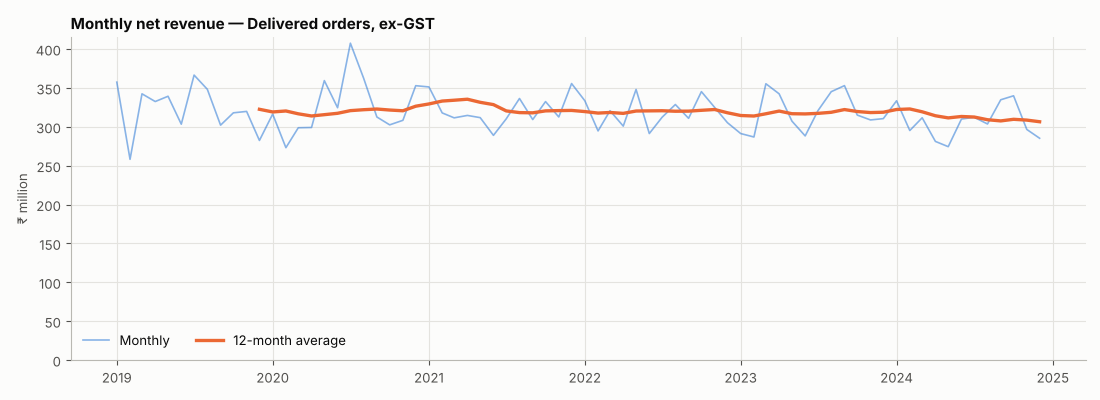

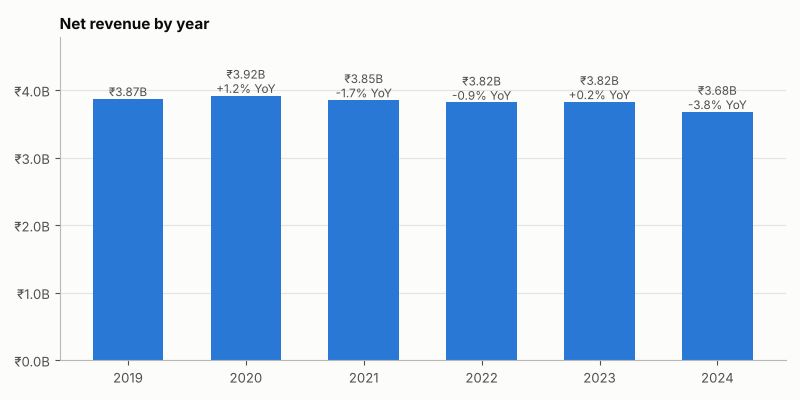

In [6]:
fig, ax = figs(size=(11,4))
m = rev_month.set_index("order_month").net_revenue/1e6
ax.plot(m.index, m.values, lw=1.2, color=BLUE, alpha=.55, label="Monthly")
ax.plot(m.index, m.rolling(12).mean(), lw=2.4, color=ORANGE, label="12-month average")
ax.set_title("Monthly net revenue — Delivered orders, ex-GST"); ax.set_ylabel("₹ million"); ax.set_ylim(0)
ax.legend(loc="lower left", ncol=2); savefig(fig,"01_monthly_net_revenue.png")

fig, ax = figs(size=(8,4))
ax.bar(rev_year.order_year.astype(str), rev_year.net_revenue/1e9, color=BLUE, width=.6)
for x,(v,y) in enumerate(zip(rev_year.net_revenue/1e9, rev_year.yoy_pct)):
    ax.text(x, v+.04, f"₹{v:.2f}B" + ("" if np.isnan(y) else f"\n{y:+.1f}% YoY"), ha="center", fontsize=8.5, color=INK2)
ax.set_ylim(0, rev_year.net_revenue.max()/1e9*1.22); ax.set_title("Net revenue by year"); ax.grid(axis="x", visible=False)
billions(ax,"y"); savefig(fig,"01b_net_revenue_by_year.png")

## A.3 Net revenue by customer type and region

In [7]:
by_type = deliv.groupby("customer_type").agg(net_revenue=("total_order_value","sum"), avg_order_value=("total_order_value","mean"),
                                             orders=("so_id","count")).round(2).sort_values("net_revenue",ascending=False).reset_index()
by_type["share_pct"] = (by_type.net_revenue/by_type.net_revenue.sum()*100).round(1)
by_region = deliv.groupby("customer_region").agg(net_revenue=("total_order_value","sum"), orders=("so_id","count")).round(2).sort_values("net_revenue",ascending=False).reset_index()
by_region["share_pct"] = (by_region.net_revenue/by_region.net_revenue.sum()*100).round(1)
save(by_type,"kpi_revenue_by_customer_type.csv"); save(by_region,"kpi_revenue_by_region.csv")
display(by_type); display(by_region)
top2 = by_region.head(2).share_pct.sum(); print(f"Top-2 regions share of net revenue: {top2:.1f}%")

saved kpi_revenue_by_customer_type.csv (5 rows)
saved kpi_revenue_by_region.csv (6 rows)
Top-2 regions share of net revenue: 60.9%


  customer_type  net_revenue  avg_order_value  orders  share_pct
0    Government   5049342920     1,239,102.56    4075      22.00
1     Corporate   4717364970     1,284,685.45    3672      20.50
2        Dealer   4683087090     1,289,041.31    3633      20.40
3   Fleet Owner   4411907790     1,276,224.41    3457      19.20
4        Retail   4097284660     1,282,003.96    3196      17.80

  customer_region  net_revenue  orders  share_pct
0           South   7261744460    5722      31.60
1            West   6730779040    5335      29.30
2            East   4051950040    3161      17.60
3           North   3938165590    3029      17.20
4         Central    501842570     406       2.20
5      North East    474505730     380       2.10

saved chart 02_03_revenue_by_type_and_region.png
saved chart 03b_region_year_heatmap.png


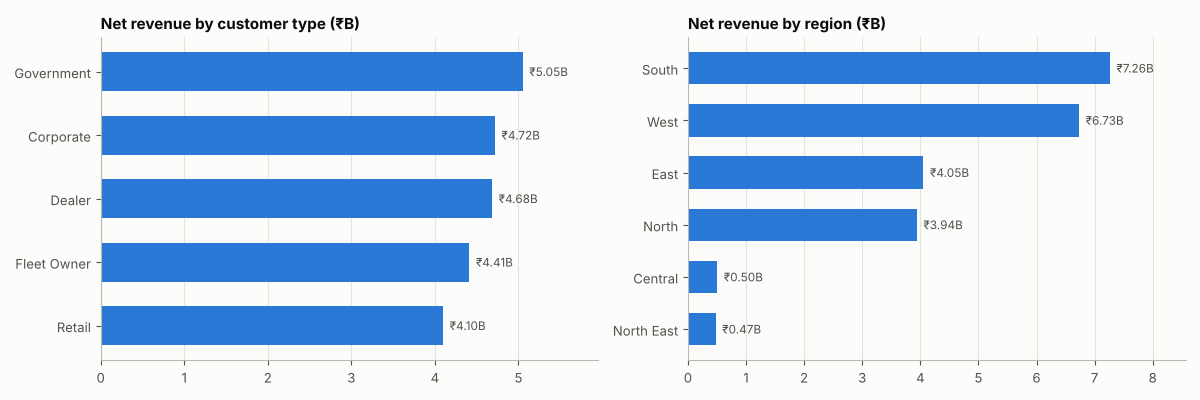

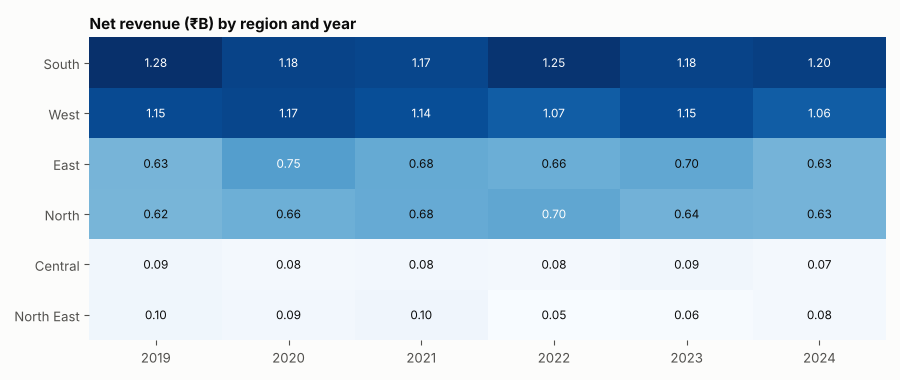

In [8]:
fig, axs = figs(1,2,size=(12,4))
hbar(axs[0], by_type.customer_type, by_type.net_revenue/1e9, "Net revenue by customer type (₹B)", fmt="₹{:.2f}B")
hbar(axs[1], by_region.customer_region, by_region.net_revenue/1e9, "Net revenue by region (₹B)", fmt="₹{:.2f}B")
savefig(fig,"02_03_revenue_by_type_and_region.png")

# year × region heat-map (single-hue sequential)
hm = deliv.pivot_table(index="customer_region", columns="order_year", values="total_order_value", aggfunc="sum").loc[by_region.customer_region]/1e9
fig, ax = figs(size=(9,3.8)); im = ax.imshow(hm.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns); ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index); ax.grid(False)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i,j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if v > hm.values.max()*.55 else INK)
ax.set_title("Net revenue (₹B) by region and year"); ax.spines[:].set_visible(False)
savefig(fig,"03b_region_year_heatmap.png")

## A.4 Delivery lead time (Delivered orders)

saved kpi_lead_time_by_region.csv (6 rows)
saved chart 04_delivery_lead_time_distribution.png


  customer_region  avg_lead_time_days  orders
0         Central                7.56     406
3      North East                7.72     380
1            East                7.94    3161
2           North                8.00    3029
4           South                8.13    5722
5            West                8.16    5335

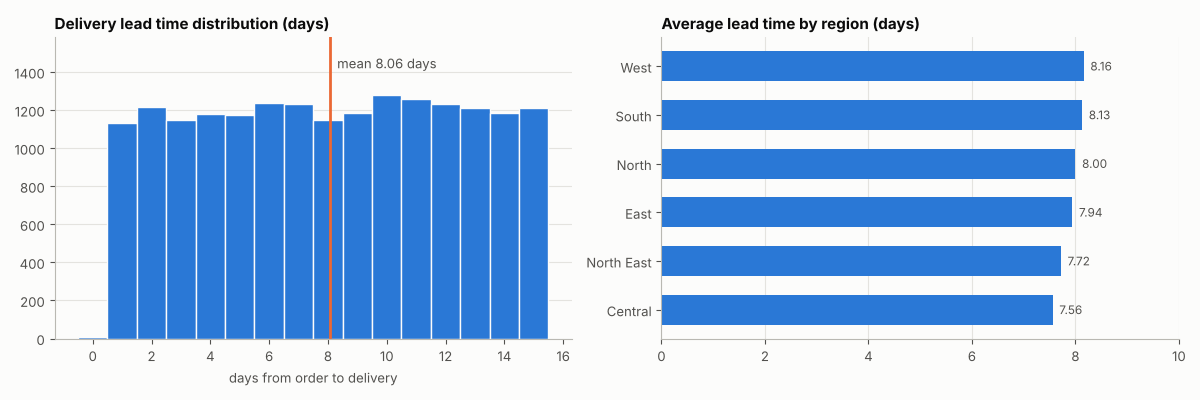

In [9]:
lt_region = deliv.groupby("customer_region").lead_time_days.agg(avg_lead_time_days="mean", orders="count").round(2).reset_index().sort_values("avg_lead_time_days")
save(lt_region,"kpi_lead_time_by_region.csv")
fig, axs = figs(1,2,size=(12,4))
axs[0].hist(deliv.lead_time_days, bins=np.arange(-.5,deliv.lead_time_days.max()+1.5,1), color=BLUE, edgecolor=SURF)
axs[0].set_ylim(0, axs[0].get_ylim()[1]*1.18)
axs[0].axvline(deliv.lead_time_days.mean(), color=ORANGE, lw=2); axs[0].text(deliv.lead_time_days.mean()+.25, axs[0].get_ylim()[1]*.94, f"mean {deliv.lead_time_days.mean():.2f} days", color=INK2, va="top")
axs[0].set_title("Delivery lead time distribution (days)"); axs[0].set_xlabel("days from order to delivery"); axs[0].grid(axis="x", visible=False)
hbar(axs[1], lt_region.customer_region[::-1], lt_region.avg_lead_time_days[::-1], "Average lead time by region (days)", fmt="{:.2f}")
axs[1].set_xlim(0, 10); savefig(fig,"04_delivery_lead_time_distribution.png")
lt_region

## A.5 Top products — net revenue and gross profit (Delivered lines)

saved kpi_top_products.csv (30 rows)
Top-2 products' share of net revenue: 36.0%
saved chart 05_top_products_by_net_revenue.png


  product_id                  product_name  net_revenue  gross_profit  units_sold  margin_pct  revenue_share_pct
0       P015           Engine Block EB-600   4856985000     959152500       40815       19.70              21.20
1       P014  Transmission Assembly TA-800   3387929000     608610000       40574       18.00              14.80
2       P021          Boom Cylinder BC-400   1934116800     443758400       41864       22.90               8.40
3       P019           Swing Motor SWM-350   1653411400     357269800       41543       21.60               7.20
4       P004             Track Chain TC-45   1627461800     298504300       40891       18.30               7.10
5       P010           Turbocharger TB-900   1475990800     253752000       42292       17.20               6.40
6       P011     Hydraulic Cylinder HC-200   1161766800     256767300       42093       22.10               5.10
7       P001         Hydraulic Pump HP-300   1011948000     229237200       41304       22.70   

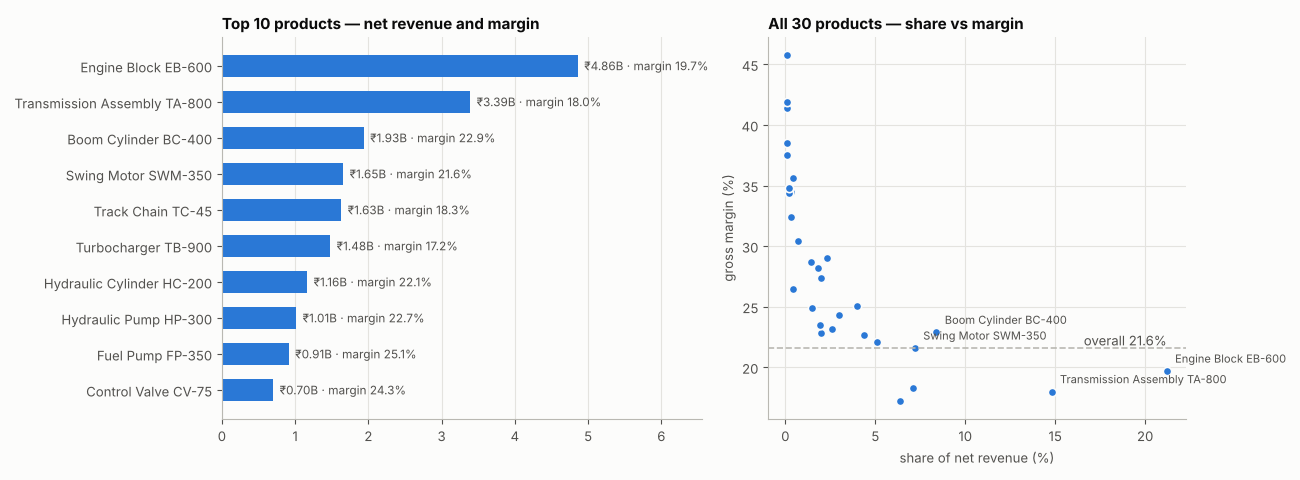

In [10]:
top_products = (sales_d.groupby(["product_id","product_name"]).agg(net_revenue=("line_total","sum"), gross_profit=("line_profit","sum"), units_sold=("quantity","sum"))
                .round(2).reset_index())
top_products["margin_pct"] = (top_products.gross_profit/top_products.net_revenue*100).round(1)
top_products["revenue_share_pct"] = (top_products.net_revenue/top_products.net_revenue.sum()*100).round(1)
top_products = top_products.sort_values("net_revenue",ascending=False).reset_index(drop=True)
save(top_products,"kpi_top_products.csv")
print(f"Top-2 products' share of net revenue: {top_products.head(2).revenue_share_pct.sum():.1f}%")
t = top_products.head(10); overall = sales_d.line_profit.sum()/sales_d.line_total.sum()*100
fig, axs = figs(1,2,size=(13,4.8), gridspec_kw={"width_ratios":[1.15,1]})
y = np.arange(len(t))[::-1]; axs[0].barh(y, t.net_revenue/1e9, color=BLUE, height=.62); axs[0].set_yticks(y); axs[0].set_yticklabels(t.product_name)
for yi,(v,m_) in zip(y, zip(t.net_revenue/1e9, t.margin_pct)): axs[0].text(v, yi, f"  ₹{v:.2f}B · margin {m_:.1f}%", va="center", fontsize=8.5, color=INK2)
axs[0].set_title("Top 10 products — net revenue and margin"); axs[0].grid(axis="y", visible=False); axs[0].margins(x=.35)
axs[1].scatter(top_products.revenue_share_pct, top_products.margin_pct, s=36, color=BLUE, edgecolor=SURF, linewidth=1.2)
axs[1].axhline(overall, color=MUTED, lw=1.2, ls="--"); axs[1].text(top_products.revenue_share_pct.max(), overall+.25, f"overall {overall:.1f}%", ha="right", color=INK2)
for r in top_products.head(4).itertuples(): axs[1].annotate(r.product_name, (r.revenue_share_pct, r.margin_pct), xytext=(6,6), textcoords="offset points", fontsize=8, color=INK2)
axs[1].set_xlabel("share of net revenue (%)"); axs[1].set_ylabel("gross margin (%)"); axs[1].set_title("All 30 products — share vs margin")
savefig(fig,"05_top_products_by_net_revenue.png")
top_products.head(10)

## A.6 Order status & payment status
Invoice `payment_status` is a field on the invoice. **All 18,033 invoices (including the 393 repeated-ID rows) are in the base**; the 1,967 Cancelled orders have no invoice.

saved kpi_payment_status_breakdown.csv (3 rows)
saved kpi_order_status.csv (2 rows)
saved chart 06a_order_and_payment_status.png


                   status  orders  pct_of_orders
0    Invoiced (Delivered)   18033          90.20
1  Cancelled (no invoice)    1967           9.80

   payment_status  invoices  invoice_value_incl_gst  pct_of_invoices  pct_of_value
0            Paid     12536       20,300,651,760.20            69.50         69.40
1  Partially Paid      3660        5,969,109,945.80            20.30         20.40
2          Unpaid      1837        2,984,231,456.40            10.20         10.20

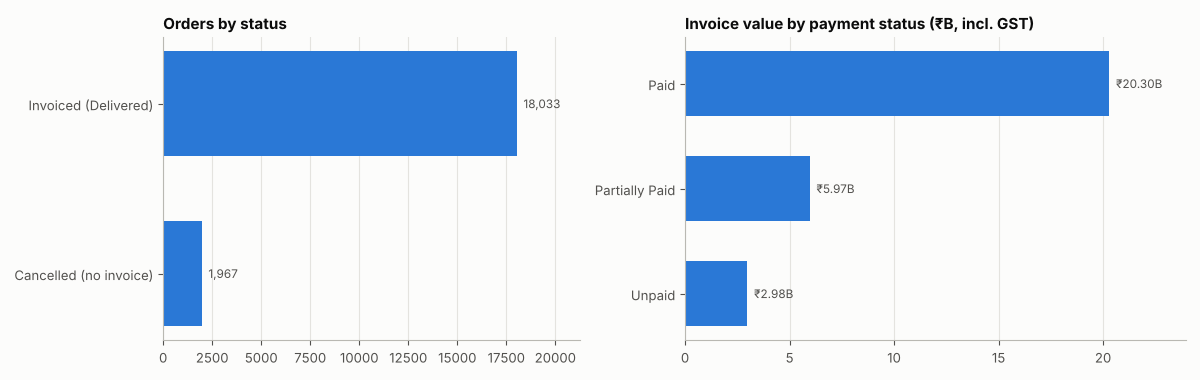

In [11]:
# every Delivered order has exactly one invoice row; Cancelled orders have none
check("invoices == delivered orders", len(deliv), len(inv), len(inv)==len(deliv))
check("invoiced orders are exactly the Delivered ones", 0, len(set(inv.so_id)^set(deliv.so_id)), set(inv.so_id)==set(deliv.so_id))

ps = inv.groupby("payment_status").agg(invoices=("row_key","count"), invoice_value_incl_gst=("grand_total","sum")).round(2)
ps["pct_of_invoices"] = (ps.invoices/ps.invoices.sum()*100).round(1)
ps["pct_of_value"]    = (ps.invoice_value_incl_gst/ps.invoice_value_incl_gst.sum()*100).round(1)
ps = ps.reindex(["Paid","Partially Paid","Unpaid"]).reset_index()
order_status_tbl = pd.DataFrame({"status":["Invoiced (Delivered)","Cancelled (no invoice)"], "orders":[len(deliv),len(cancel)]})
order_status_tbl["pct_of_orders"] = (order_status_tbl.orders/20000*100).round(1)
save(ps,"kpi_payment_status_breakdown.csv"); save(order_status_tbl,"kpi_order_status.csv")
display(order_status_tbl); display(ps)

fig, axs = figs(1,2,size=(12,3.8), gridspec_kw={"width_ratios":[1,1.2]})
hbar(axs[0], order_status_tbl.status, order_status_tbl.orders, "Orders by status", fmt="{:,.0f}")
hbar(axs[1], ps.payment_status, ps.invoice_value_incl_gst/1e9, "Invoice value by payment status (₹B, incl. GST)", fmt="₹{:.2f}B")
savefig(fig,"06a_order_and_payment_status.png")

## A.7 Outstanding, overdue & credit-risk concentration
Only invoices with a **reliable** payment total (`payment_total_reliable = True`, i.e. a unique `invoice_id`) are used for money outstanding. The 393 repeated-ID invoices are reported separately.

In [12]:
rel = inv[inv.payment_total_reliable].copy(); unrel = inv[~inv.payment_total_reliable]
check("reliable + unreliable == invoices", len(inv), len(rel)+len(unrel), len(rel)+len(unrel)==len(inv))
check("no negative outstanding", 0, int((rel.outstanding_amount<-0.5).sum()), not (rel.outstanding_amount<-0.5).any())
check("Paid invoices (reliable) fully paid", 0, int(((rel.payment_status=="Paid")&(rel.outstanding_amount.abs()>1)).sum()), not ((rel.payment_status=="Paid")&(rel.outstanding_amount.abs()>1)).any())

as_of = inv.as_of_date.iloc[0]
summary = pd.DataFrame([
 {"metric":"As-of date (latest invoice due date)", "value":as_of.date()},
 {"metric":"Invoices with reliable payment data",  "value":len(rel)},
 {"metric":"Invoices excluded (repeated invoice_id)", "value":len(unrel)},
 {"metric":"Invoice value excluded, incl. GST (₹)", "value":round(unrel.grand_total.sum(),2)},
 {"metric":"Total outstanding, reliable rows (₹)", "value":round(rel.outstanding_amount.sum(),2)},
 {"metric":"Overdue invoices (reliable)", "value":int(rel.is_overdue.sum())},
])
save(summary,"kpi_outstanding_summary.csv")

bins=[-1,0,30,90,180,365,10**6]; labels=["Not overdue","1–30","31–90","91–180","181–365",">365"]
rel["aging_bucket"]=pd.cut(rel.days_overdue.where(rel.is_overdue,0), bins=bins, labels=labels)
aging = rel.groupby("aging_bucket",observed=False).agg(invoices=("row_key","count"), outstanding=("outstanding_amount","sum")).round(2).reset_index()
save(aging,"kpi_payment_aging.csv")

def unpaid_conc(col):
    g = rel.groupby(col).agg(invoices=("row_key","count"), invoice_value=("grand_total","sum"), outstanding=("outstanding_amount","sum"),
                             unpaid_invoices=("payment_status", lambda s:(s=="Unpaid").sum())).reset_index()
    g["outstanding_pct_of_value"]=(g.outstanding/g.invoice_value*100).round(1); g["unpaid_pct_of_invoices"]=(g.unpaid_invoices/g.invoices*100).round(1)
    return g.round(2).sort_values("outstanding_pct_of_value",ascending=False)
risk_type=unpaid_conc("customer_type"); risk_region=unpaid_conc("customer_region")
save(risk_type,"kpi_credit_risk_by_customer_type.csv"); save(risk_region,"kpi_credit_risk_by_region.csv")
display(summary); display(aging); display(risk_type); display(risk_region)

saved kpi_outstanding_summary.csv (6 rows)
saved kpi_payment_aging.csv (6 rows)
saved kpi_credit_risk_by_customer_type.csv (5 rows)
saved kpi_credit_risk_by_region.csv (6 rows)


                                    metric            value
0     As-of date (latest invoice due date)       2025-03-14
1      Invoices with reliable payment data            17640
2  Invoices excluded (repeated invoice_id)              393
3    Invoice value excluded, incl. GST (₹)   654,355,301.80
4     Total outstanding, reliable rows (₹) 5,804,303,956.73
5              Overdue invoices (reliable)             5375

  aging_bucket  invoices      outstanding
0  Not overdue     12265       991,895.35
1         1–30        17    13,592,957.78
2        31–90       119   114,828,267.65
3       91–180       224   241,460,410.56
4      181–365       420   444,660,435.64
5         >365      4595 4,988,769,989.75

  customer_type  invoices    invoice_value      outstanding  unpaid_invoices  outstanding_pct_of_value  unpaid_pct_of_invoices
0     Corporate      3589 5,865,847,362.60 1,256,285,234.89              396                     21.40                   11.00
2   Fleet Owner      3379 5,495,099,289.40 1,124,720,951.50              350                     20.50                   10.40
1        Dealer      3567 5,867,524,564.40 1,172,186,964.96              365                     20.00                   10.20
3    Government      3975 6,256,016,038.00 1,246,265,410.21              401                     19.90                   10.10
4        Retail      3130 5,115,150,606.20 1,004,845,395.17              286                     19.60                    9.10

  customer_region  invoices    invoice_value      outstanding  unpaid_invoices  outstanding_pct_of_value  unpaid_pct_of_invoices
1            East      3090 5,048,097,617.20 1,054,734,933.39              289                     20.90                    9.40
4           South      5601 9,063,664,206.00 1,895,045,062.31              608                     20.90                   10.90
0         Central       399   632,374,897.00   129,351,923.19               47                     20.50                   11.80
5            West      5210 8,364,129,354.20 1,678,382,337.42              504                     20.10                    9.70
2           North      2973 4,911,101,771.80   939,004,119.50              318                     19.10                   10.70
3      North East       367   580,270,014.40   107,785,580.92               32                     18.60                    8.70

saved chart 06_payment_aging.png
saved chart 06b_credit_risk_by_segment.png


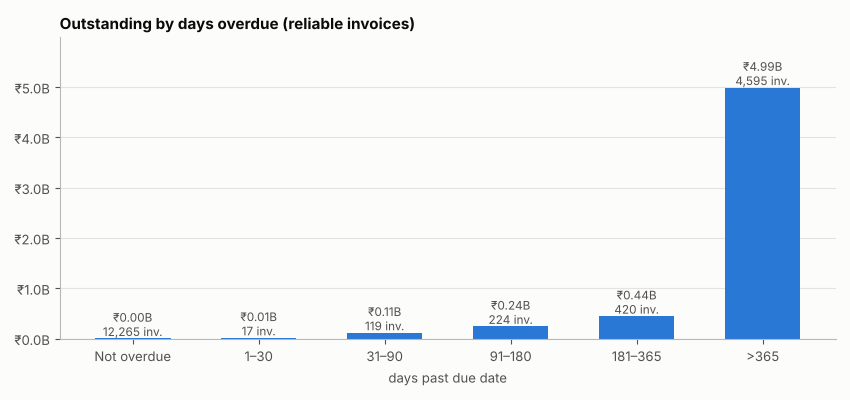

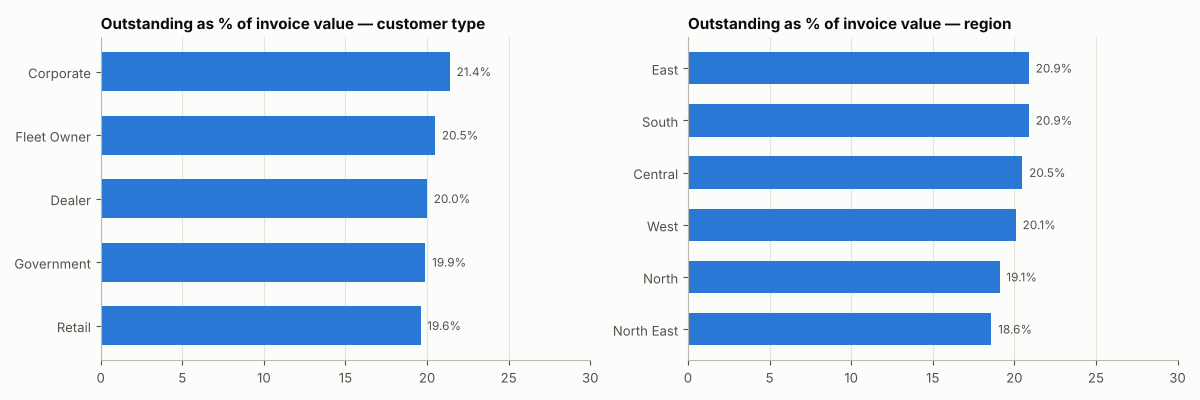

In [13]:
fig, ax = figs(size=(8.5,4))
ax.bar(aging.aging_bucket.astype(str), aging.outstanding/1e9, color=BLUE, width=.6)
for x,(v,n) in enumerate(zip(aging.outstanding/1e9, aging.invoices)): ax.text(x, v+.05, f"₹{v:.2f}B\n{n:,} inv.", ha="center", fontsize=8.5, color=INK2)
ax.set_ylim(0, aging.outstanding.max()/1e9*1.2); ax.set_title("Outstanding by days overdue (reliable invoices)"); ax.set_xlabel("days past due date"); ax.grid(axis="x", visible=False)
billions(ax,"y"); savefig(fig,"06_payment_aging.png")

# credit risk: is outstanding concentrated anywhere?  (shared 0–30% axis so differences are not exaggerated)
fig, axs = figs(1,2,size=(12,4), sharex=True)
hbar(axs[0], risk_type.customer_type, risk_type.outstanding_pct_of_value, "Outstanding as % of invoice value — customer type", fmt="{:.1f}%")
hbar(axs[1], risk_region.customer_region, risk_region.outstanding_pct_of_value, "Outstanding as % of invoice value — region", fmt="{:.1f}%")
for a in axs: a.set_xlim(0,30)
savefig(fig,"06b_credit_risk_by_segment.png")

# Part B — Supplier KPIs (from purchase orders)
Supplier performance is measured on **what was actually bought and received**. A product→supplier mapping is *not* used: the purchase history shows every product is bought from every supplier (checked below).

In [14]:
# ── Is there a primary supplier per product? ────────────────────────────────
cov = po.groupby("product_id").supplier_id.nunique()
share = po.groupby(["product_id","supplier_id"]).size().groupby(level=0).apply(lambda s:s.max()/s.sum())
check("suppliers per product", "8 (all suppliers buy every product)", f"min {cov.min()} / max {cov.max()}", cov.min()==8)
print(f"Suppliers per product: min {cov.min()}, max {cov.max()}  |  mean share of the top supplier per product: {share.mean():.1%} (equal split would be 12.5%)")
print("→ no product has a meaningful 'primary' supplier; supplier-level KPIs are computed from PO activity instead.")

pos = po.drop_duplicates("po_id").copy()
check("PO headers", 24000, len(pos), len(pos)==24000)
recv = po[po.po_status=="Received"].copy(); recv["on_time"] = recv.delivery_delay_days<=0
check("cancelled POs have no received_date", 0, int(po[po.po_status=="Cancelled"].received_date.notna().sum()), not po[po.po_status=="Cancelled"].received_date.notna().any())

sp = recv.groupby(["supplier_id","supplier_name","supplier_type"]).agg(
        received_lines=("po_id","count"), units_received=("quantity","sum"), spend_ex_gst=("line_total","sum"),
        on_time_rate_pct=("on_time", lambda s:s.mean()*100), avg_delay_days=("delivery_delay_days","mean"),
        avg_actual_lead_days=("lead_time_actual_days","mean"), contract_lead_days=("supplier_lead_days","first"),
        reliability_score=("reliability_score","first")).reset_index()
canc = pos.groupby("supplier_id").agg(pos_total=("po_id","count"), pos_cancelled=("po_status", lambda s:(s=="Cancelled").sum())).reset_index()
canc["cancel_rate_pct"]=canc.pos_cancelled/canc.pos_total*100
sp = sp.merge(canc,on="supplier_id")
sp["spend_share_pct"]=sp.spend_ex_gst/sp.spend_ex_gst.sum()*100
sp = sp.round(2).sort_values("spend_ex_gst",ascending=False).reset_index(drop=True)
save(sp,"kpi_supplier_performance.csv"); sp

Suppliers per product: min 8, max 8  |  mean share of the top supplier per product: 13.3% (equal split would be 12.5%)
→ no product has a meaningful 'primary' supplier; supplier-level KPIs are computed from PO activity instead.
saved kpi_supplier_performance.csv (8 rows)


  supplier_id                    supplier_name supplier_type  received_lines  units_received      spend_ex_gst  on_time_rate_pct  avg_delay_days  avg_actual_lead_days  contract_lead_days  reliability_score  pos_total  pos_cancelled  cancel_rate_pct  spend_share_pct
0     SUP0005             Tianjin OEM Supplies           OEM           17987         2875531 40,256,023,887.03             85.33            0.48                 28.48                  28                  3       3044            290             9.53            12.90
1     SUP0001            Shenzhen OEM Supplies           OEM           17490         2802989 39,439,157,083.27             85.27            0.48                 19.48                  19                  5       2944            291             9.88            12.64
2     SUP0008            Hangzhou OEM Supplies           OEM           17379         2777131 39,246,104,325.24             84.15            0.54                 26.54                  26                

                  supplier_name  reliability_score  on_time_rate_pct  avg_delay_days  cancel_rate_pct
           Tianjin OEM Supplies                  3             85.33            0.48             9.53
          Shenzhen OEM Supplies                  5             85.27            0.48             9.88
          Hangzhou OEM Supplies                  4             84.15            0.54             9.57
  Shanghai Distributor Supplies                  4             85.42            0.53            10.22
   Qingdao Distributor Supplies                  3             85.60            0.48             9.41
   Suzhou Local Vendor Supplies                  5             84.33            0.55             9.94
    Ningbo Distributor Supplies                  3             84.43            0.51            10.18
Guangzhou Local Vendor Supplies                  5             85.03            0.51            10.28
corr(reliability_score, on_time_rate): -0.2
saved chart 07_supplier_spend_and_on_t

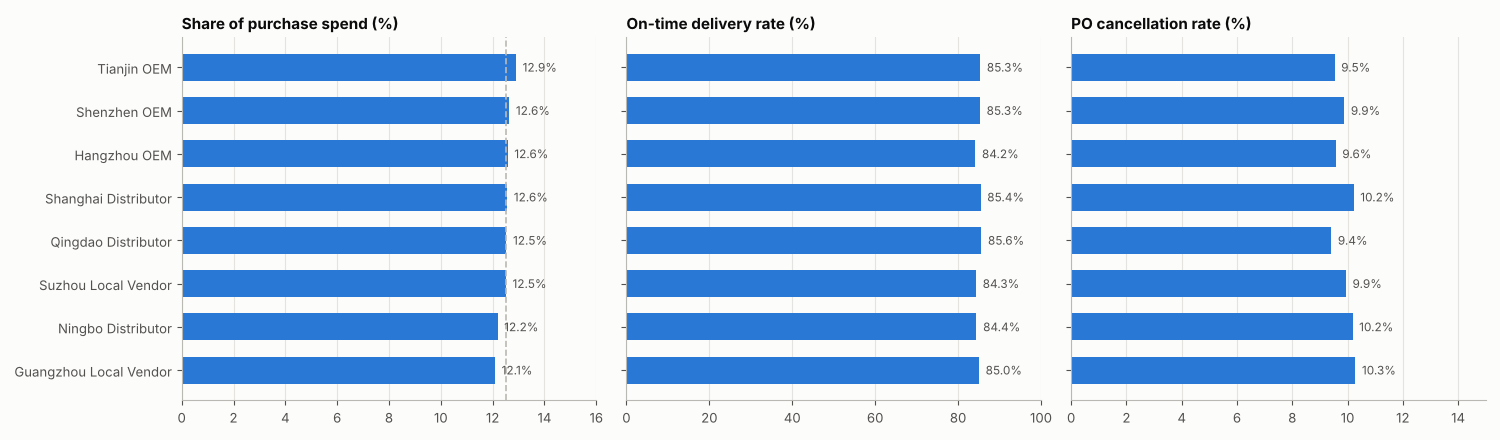

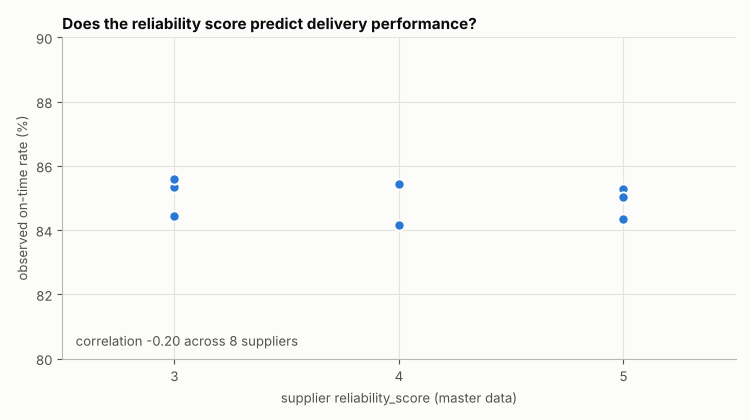

In [15]:
# does reliability_score relate to observed on-time rate?
print(sp[["supplier_name","reliability_score","on_time_rate_pct","avg_delay_days","cancel_rate_pct"]].to_string(index=False))
print("corr(reliability_score, on_time_rate):", round(sp.reliability_score.corr(sp.on_time_rate_pct),2))
names = sp.supplier_name.str.replace(" Supplies","")
fig, axs = figs(1,3,size=(15,4.4))
hbar(axs[0], names, sp.spend_share_pct, "Share of purchase spend (%)", fmt="{:.1f}%"); axs[0].axvline(12.5, color=MUTED, ls="--", lw=1.2); axs[0].set_xlim(0,16)
hbar(axs[1], names, sp.on_time_rate_pct, "On-time delivery rate (%)", fmt="{:.1f}%"); axs[1].set_xlim(0,100)
hbar(axs[2], names, sp.cancel_rate_pct, "PO cancellation rate (%)", fmt="{:.1f}%"); axs[2].set_xlim(0,15)
for a in axs[1:]: a.set_yticklabels([])
savefig(fig,"07_supplier_spend_and_on_time.png")

fig, ax = figs(size=(7.5,4.2))
ax.scatter(sp.reliability_score, sp.on_time_rate_pct, s=55, color=BLUE, edgecolor=SURF, linewidth=1.4)
ax.set_xlim(2.5,5.5); ax.set_ylim(80,90); ax.set_xticks([3,4,5]); ax.set_xlabel("supplier reliability_score (master data)"); ax.set_ylabel("observed on-time rate (%)")
ax.set_title("Does the reliability score predict delivery performance?")
ax.text(.02,.04,f"correlation {sp.reliability_score.corr(sp.on_time_rate_pct):+.2f} across 8 suppliers", transform=ax.transAxes, color=INK2)
savefig(fig,"07b_reliability_vs_observed.png")

# Part C — Product, Inventory & Warehouse
### C.1 Stock-scale diagnostic (replaces the quantile "stock health" and stock-based turnover)
`current_stock` is ~100,000 units per product/branch while `max_stock`, `reorder_level` and `safety_stock` are in the tens-to-hundreds. The cause is visible in the flows: **purchases received dwarf units sold**, so the ledger balance grows far beyond the thresholds, which are sized to sales volumes.

In [16]:
sc = invl[["current_stock","max_stock","reorder_level","safety_stock","opening_stock"]].describe().T.round(2)
display(sc); save(sc.reset_index().rename(columns={"index":"field"}),"kpi_stock_scale_check.csv")

units_sold_deliv = sales_d.quantity.sum(); units_sold_all = sales.quantity.sum(); units_recv = recv.quantity.sum()
ledger_in  = led.loc[led.movement_type=="IN","quantity"].sum(); ledger_out = led.loc[led.movement_type=="OUT","quantity"].sum()
flow = pd.DataFrame([
  {"measure":"Units sold (Delivered orders)","units":units_sold_deliv},
  {"measure":"Units received on purchase orders","units":units_recv},
  {"measure":"Ledger IN units","units":ledger_in},{"measure":"Ledger OUT units","units":ledger_out},
])
ratio = units_recv/units_sold_deliv
print(f"Units received ÷ units sold = {ratio:.1f}×   |   ledger IN ÷ OUT = {ledger_in/ledger_out:.1f}×")
print(f"Pairs with current_stock >= max_stock: {(invl.current_stock>=invl.max_stock).sum()} of {len(invl)}   |   below reorder level: {int(invl.below_reorder.sum())}")
check("scale diagnostic: all pairs exceed max_stock", 180, int((invl.current_stock>=invl.max_stock).sum()), (invl.current_stock>=invl.max_stock).all())
save(flow,"kpi_stock_scale_flows.csv"); flow

saved kpi_stock_scale_check.csv (5 rows)
Units received ÷ units sold = 18.1×   |   ledger IN ÷ OUT = 18.1×
Pairs with current_stock >= max_stock: 180 of 180   |   below reorder level: 0
saved kpi_stock_scale_flows.csv (4 rows)


               count       mean      std       min        25%        50%        75%        max
current_stock 180.00 107,240.37 5,341.09 88,853.00 103,487.50 107,790.50 110,779.50 121,013.00
max_stock     180.00     321.76   116.55    131.00     230.00     310.50     415.50     582.00
reorder_level 180.00      64.55    24.06     24.00      44.00      62.00      82.25     119.00
safety_stock  180.00      45.21    16.87     16.00      31.00      43.50      58.00      85.00
opening_stock 180.00     183.16    63.44     80.00     129.00     178.50     234.50     300.00

                             measure     units
0      Units sold (Delivered orders)   1234939
1  Units received on purchase orders  22387123
2                    Ledger IN units  20397795
3                   Ledger OUT units   1124832

saved kpi_inventory_turnover.csv (30 rows)
saved chart 08_received_vs_sold_by_product.png
saved chart 08b_stock_scale_gap.png
NOTE: indicative_turnover = units sold ÷ avg stock. It is NOT a valid performance KPI until the stock scale is confirmed with the data owner.


   product_id  units_sold  units_received  avg_current_stock                  product_name       category  received_to_sold_ratio  indicative_turnover
23       P024       39486          757049         109,364.67            Track Roller TR-60  Undercarriage                   19.20                 0.36
4        P005       40480          759066         109,803.33          Fuel Injector FI-220         Engine                   18.80                 0.37
22       P023       40276          758185         110,253.33             Idler Wheel IW-55  Undercarriage                   18.80                 0.36
13       P014       40574          764100         110,277.17  Transmission Assembly TA-800   Transmission                   18.80                 0.37
1        P002       40917          764701         109,168.67       Engine Oil Filter OF-90        Filters                   18.70                 0.38
12       P013       39927          740939         105,763.33                Seal Kit SK-15    

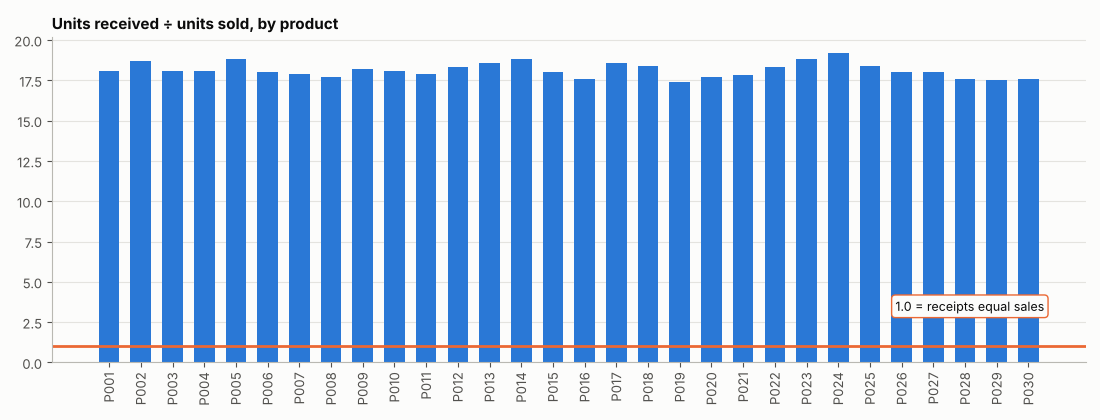

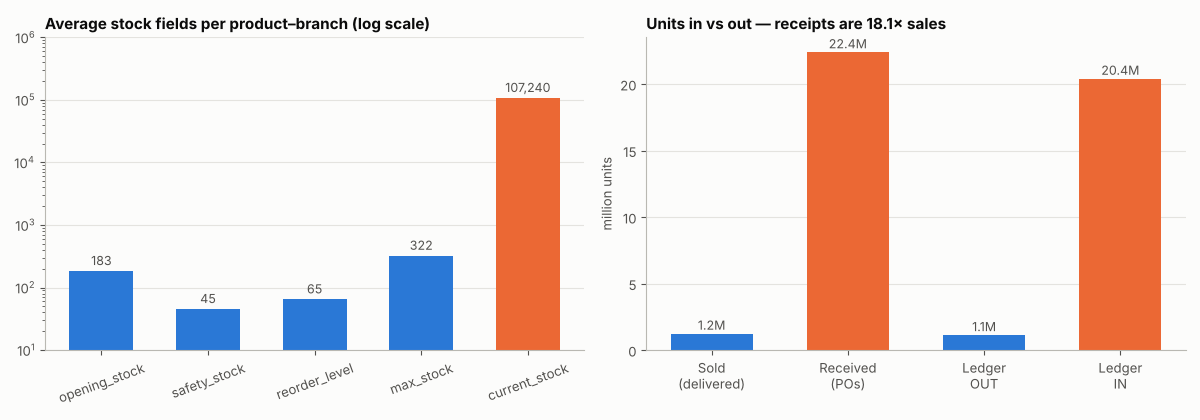

In [17]:
# per-product flows: sold vs received
pf = pd.DataFrame({
  "units_sold":     sales_d.groupby("product_id").quantity.sum(),
  "units_received": recv.groupby("product_id").quantity.sum(),
  "avg_current_stock": invl.groupby("product_id").current_stock.mean(),
}).join(invl.drop_duplicates("product_id").set_index("product_id")[["product_name","category"]]).reset_index()
pf["received_to_sold_ratio"] = (pf.units_received/pf.units_sold).round(1)
pf["indicative_turnover"]    = (pf.units_sold/pf.avg_current_stock).round(3)
pf = pf.sort_values("received_to_sold_ratio",ascending=False)
save(pf,"kpi_inventory_turnover.csv")
fig, ax = figs(size=(11,4.2)); p_ = pf.sort_values("product_id")
ax.bar(p_.product_id, p_.received_to_sold_ratio, color=BLUE, width=.65); ax.axhline(1, color=ORANGE, lw=2)
ax.text(len(p_)-.5, 3.2, "1.0 = receipts equal sales", ha="right", color=INK, fontsize=9, bbox=dict(facecolor=SURF, edgecolor=ORANGE, boxstyle="round,pad=.3"))
ax.set_title("Units received ÷ units sold, by product"); plt.setp(ax.get_xticklabels(), rotation=90); ax.grid(axis="x", visible=False)
savefig(fig,"08_received_vs_sold_by_product.png")

# the scale gap itself: log axis because the values differ by orders of magnitude
fig, axs = figs(1,2,size=(12,4.2))
vals = [invl.opening_stock.mean(), invl.safety_stock.mean(), invl.reorder_level.mean(), invl.max_stock.mean(), invl.current_stock.mean()]
labs = ["opening_stock","safety_stock","reorder_level","max_stock","current_stock"]
axs[0].bar(labs, vals, color=[BLUE]*4+[ORANGE], width=.6); axs[0].set_yscale("log"); axs[0].set_title("Average stock fields per product–branch (log scale)")
for x,v in enumerate(vals): axs[0].text(x, v*1.25, f"{v:,.0f}", ha="center", fontsize=9, color=INK2)
axs[0].set_ylim(10, 1e6); plt.setp(axs[0].get_xticklabels(), rotation=20); axs[0].grid(axis="x", visible=False)
fl = flow.set_index("measure").units/1e6
axs[1].bar(["Sold\n(delivered)","Received\n(POs)","Ledger\nOUT","Ledger\nIN"], [fl.iloc[0], fl.iloc[1], fl.iloc[3], fl.iloc[2]], color=[BLUE,ORANGE,BLUE,ORANGE], width=.6)
for x,v in enumerate([fl.iloc[0], fl.iloc[1], fl.iloc[3], fl.iloc[2]]): axs[1].text(x, v+.3, f"{v:.1f}M", ha="center", fontsize=9, color=INK2)
axs[1].set_title(f"Units in vs out — receipts are {ratio:.1f}× sales"); axs[1].set_ylabel("million units"); axs[1].grid(axis="x", visible=False)
savefig(fig,"08b_stock_scale_gap.png")
print("NOTE: indicative_turnover = units sold ÷ avg stock. It is NOT a valid performance KPI until the stock scale is confirmed with the data owner.")
pf.head(8)

### C.2 Ledger vs inventory-master reconciliation

14 of 180 product–branch pairs differ; difference range -515 to +16 units
saved kpi_stock_ledger_mismatches.csv (14 rows)
saved chart 09_stock_ledger_mismatches.png


    product_id branch_id  current_stock  ledger_latest_balance  balance_difference  total_movements  total_adjustment_qty
8         P002    CHN001         105885                 106182                -297             1462                   326
19        P004    PUN001         104859                 105024                -165             1242                   605
47        P008    AHM001         109281                 109317                 -36             1350                   431
59        P010    AHM001         115149                 115549                -400             1400                   211
120       P021    DEL001         115902                 116107                -205             1258                   494
135       P023    HYD001         105798                 105981                -183             1134                   252
147       P025    HYD001         113613                 114128                -515             1271                   207
151       P026    PUN001

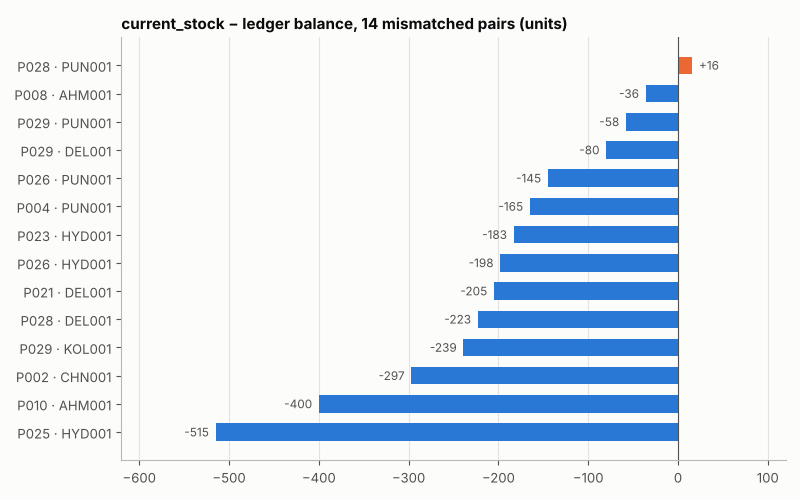

In [18]:
mism = invl[invl.balance_mismatch][["product_id","branch_id","current_stock","ledger_latest_balance","balance_difference","total_movements","total_adjustment_qty"]]
check("stock vs ledger mismatches", 14, len(mism), len(mism)==14)
print(f"{len(mism)} of {len(invl)} product–branch pairs differ; difference range {mism.balance_difference.min():+,.0f} to {mism.balance_difference.max():+,.0f} units")
save(mism,"kpi_stock_ledger_mismatches.csv")
mm_ = mism.assign(pair=mism.product_id+" · "+mism.branch_id).sort_values("balance_difference")
fig, ax = figs(size=(8,5)); cols = [ORANGE if v>0 else BLUE for v in mm_.balance_difference]
ax.barh(mm_.pair, mm_.balance_difference, color=cols, height=.62); ax.axvline(0, color=INK2, lw=.8)
for y_,v in enumerate(mm_.balance_difference): ax.text(v, y_, f"  {v:+,}" if v>0 else f"{v:+,}  ", va="center", ha="left" if v>0 else "right", fontsize=8.5, color=INK2)
ax.set_title("current_stock − ledger balance, 14 mismatched pairs (units)"); ax.set_xlim(-620, 120); ax.grid(axis="y", visible=False)
savefig(fig,"09_stock_ledger_mismatches.png")
mism

### C.3 Branch view

saved kpi_branch_summary.csv (6 rows)
saved chart 10_branch_view.png


  branch_id          branch_name  net_revenue  orders  products  avg_current_stock  stock_value_cost  mismatched_pairs region  total_employees  warehouse_capacity_sqft
0    AHM001   Ahmedabad West Hub   3986314570    3115        30         105,166.40       46129795000                 2   West               63                34,120.00
1    CHN001    Chennai South Hub   4682202010    3677        30         107,808.17       47798163500                 1  South               81                41,890.00
2    DEL001        Delhi Central   3500031300    2682        30         109,622.33       47709094440                 3  North               92                45,230.00
3    HYD001  Hyderabad Logistics   3077048220    2478        30         108,176.37       47224691630                 3  South               57                36,210.00
4    KOL001   Kolkata East Depot   4339861320    3413        30         104,126.83       44702846930                 1   East               49                29

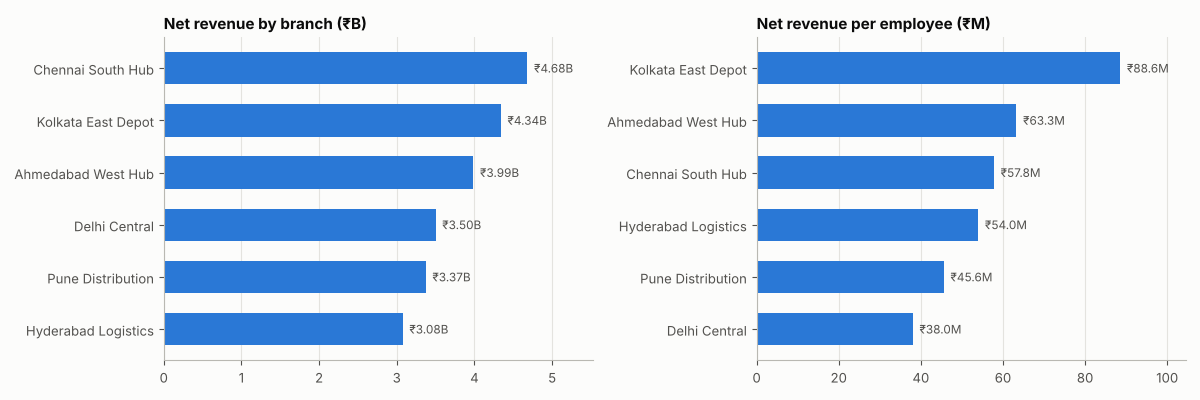

In [19]:
br_sales = deliv.groupby(["branch_id","branch_name"]).agg(net_revenue=("total_order_value","sum"), orders=("so_id","count")).round(2).reset_index()
br_stock = invl.groupby("branch_id").agg(products=("product_id","count"), avg_current_stock=("current_stock","mean"), stock_value_cost=("stock_value_cost","sum"),
                                         mismatched_pairs=("balance_mismatch","sum")).round(2).reset_index()
branch = br_sales.merge(br_stock,on="branch_id")
# optional: capacity / headcount if the branches master is available
for p in [Path("data/branches.csv"), Path("../data/branches.csv"), Path("branches.csv")]:
    if p.exists():
        b = pd.read_csv(p)[["branch_id","region","warehouse_capacity","total_employees"]]
        b["warehouse_capacity_sqft"] = b.warehouse_capacity.str.extract(r"(\d+)").astype(float)
        branch = branch.merge(b.drop(columns="warehouse_capacity"),on="branch_id",how="left"); break
save(branch,"kpi_branch_summary.csv")
bs = branch.sort_values("net_revenue", ascending=False)
fig, axs = figs(1,2,size=(12,4))
hbar(axs[0], bs.branch_name, bs.net_revenue/1e9, "Net revenue by branch (₹B)", fmt="₹{:.2f}B")
if "total_employees" in bs:
    rpe = (bs.net_revenue/bs.total_employees/1e6).sort_values(ascending=False)
    hbar(axs[1], bs.set_index("branch_name").loc[rpe.index.map(bs.branch_name)].index, rpe.values, "Net revenue per employee (₹M)", fmt="₹{:.1f}M")
savefig(fig,"10_branch_view.png")
branch

# Part D — Validation report

In [20]:
vr = pd.DataFrame(checks, columns=["Check_Item","Expected","Actual","Status"])
vr.to_csv("validation_report_week03.csv", index=False)
print(vr.to_string(index=False)); print(f"\n{(vr.Status=='PASS').sum()} / {len(vr)} checks passed")
assert (vr.Status=="PASS").all()

                                             Check_Item                            Expected        Actual Status
                                sales rows (line grain)                              130402        130402   PASS
                   sales key (so_id,line_number) unique                                   0             0   PASS
                                          unique orders                               20000         20000   PASS
                                           invoice rows                               18033         18033   PASS
                                   PO rows (line grain)                              155495        155495   PASS
                                        inventory pairs                                 180           180   PASS
                                            ledger rows                              237230        237230   PASS
                             no ambiguous _x/_y columns                                   0     